# Logistiklabb 

**Grupp:** Rikard & David



In [973]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
pd.set_option("display.precision", 2)

from IPython.display import Markdown, display

def visa_tabell(df, format={}):
    # visar en tabell som markdown, så att den blir snygg både i notebooken och i PDF:en
    kolumner = list(df.columns)
    rader = ["| " + " | ".join(str(k) for k in kolumner) + " |", "|" + "---|" * len(kolumner)]
    for _, rad in df.iterrows():
        celler = []
        for k in kolumner:
            v = rad[k]
            if k in format:
                celler.append(format[k].format(v))
            elif isinstance(v, float):
                celler.append(f"{v:.2f}")
            else:
                celler.append(str(v))
        rader.append("| " + " | ".join(celler) + " |")
    display(Markdown("\n".join(rader)))

---
# 1. Lagerstyrning och produktion
## 1a) Exponentiell utjämning

Prognosen uppdateras med

$$u(t) = a\,d(t) + (1-a)\,u(t-1), \qquad 0 \le a \le 1,$$

där $u(t-1)$ är prognosen för månad $t$ (gjord månaden innan) och $u(0)=50$ är startskattningen (prognos för januari). Prognosen för december är alltså $u(\text{nov})$.

Därefter beräknades APE (Absolute Percentage Error) för varje månad, som visar hur stort felet var mellan det verkliga och prognosiserade värdet. 

$$
\mathrm{APE}(t) = \frac{\left| d(t) - u(t-1) \right|}{d(t)} \cdot 100\,\%
$$


När felet hade beräknats för varje måndad kunde ett medelvärde (MAPE) bestämmas. 

Prognosfelet mäts med MAPE över de 11 månader där vi har utfall:

$$\text{MAPE} = \frac{100}{n}\sum_{t=1}^{n}\frac{|d(t)-u(t-1)|}{d(t)}\;\%.$$


Vikten $a$ bestämmer hur stor betydelse den senaste observationen $d(t)$ har för nästa prognos, medan $(1-a)$ är vikten för den tidigare prognosen $u(t-1)$, som bygger på alla äldre månader. Om $a = 0$ tas ingen hänsyn till förra månadens utfall, och prognosen förblir startvärdet, 50. Om $a = 1$ bygger prognosen enbart på förra månadens utfall, så nästa månads prognos blir exakt samma värde som föregående månad. 

Om $a = 0$ så kommer MAPE vara 14.0% men om $a = 1$ så kommer MAPE vara CA 20.0%. Genom att testa olika $a$ mellan 0 till 1 så kommer MAPE:n variera mellan 14-20 %.    

In [974]:
manader = ["jan","feb","mar","apr","maj","jun","jul","aug","sep","okt","nov","dec"]
d = np.array([52, 51, 60, 46, 70, 50, 39, 48, 60, 70, 60], dtype=float)
u0 = 50.0

def utjamning(a, d=d, u0=u0):
    # Returnerar prognoserna u(t-1) för jan..dec (12 värden)
    u = [u0]
    for dt in d:
        u.append(a*dt + (1-a)*u[-1])
    return np.array(u)

def mape(a):
    u = utjamning(a)
    return 100*np.mean(np.abs(d - u[:-1]) / d)

alfa = np.round(np.arange(0, 1.01, 0.1), 1)
tabell = pd.DataFrame({
    "a": alfa,
    "Prognos dec": [utjamning(a)[-1] for a in alfa],
    "MAPE (%)": [mape(a) for a in alfa],
})
visa_tabell(tabell, {"a": "{:.1f}"})

| a | Prognos dec | MAPE (%) |
|---|---|---|
| 0.0 | 50.00 | 14.00 |
| 0.1 | 54.15 | 14.45 |
| 0.2 | 56.66 | 14.93 |
| 0.3 | 58.48 | 15.26 |
| 0.4 | 59.90 | 15.37 |
| 0.5 | 60.94 | 16.20 |
| 0.6 | 61.56 | 17.31 |
| 0.7 | 61.74 | 18.29 |
| 0.8 | 61.49 | 19.11 |
| 0.9 | 60.89 | 19.79 |
| 1.0 | 60.00 | 20.31 |



### Härledning av den rekursiva formeln

Utgå från den viktade summan av hela tidsserien där vikterna avtar geometriskt:

$$u(t) = a\,d(t) + a(1-a)\,d(t-1) + a(1-a)^2 d(t-2) + \dots + (1-a)^t u(0)
= a\sum_{k=0}^{t-1}(1-a)^k d(t-k) + (1-a)^t u(0).$$

Skriv motsvarande uttryck för $u(t-1)$ och multiplicera med $(1-a)$:

$$(1-a)\,u(t-1) = a\sum_{k=0}^{t-2}(1-a)^{k+1} d(t-1-k) + (1-a)^t u(0) = a\sum_{k=1}^{t-1}(1-a)^{k} d(t-k) + (1-a)^t u(0).$$

Det är exakt alla termer i $u(t)$ utom den första, $a\,d(t)$. Alltså

$$u(t) = a\,d(t) + (1-a)\,u(t-1).$$

Vikterna $a(1-a)^k$ summerar (tillsammans med $(1-a)^t$) till 1, så det är ett riktigt viktat medelvärde där äldre observationer väger exponentiellt mindre.

## 1b) ABC-analys

Lagervärde per artikel = antal $\times$ medelkostnad. Artiklarna sorteras efter lagervärde och den kumulativa andelen beräknas för att göra analysen. Gränsen dras vid A = de första 80 % av värdet, B = 80-95 % och C de sista 5 %.

### Lösning i Excel

Analysen är gjord i Excel och arbetsgången är följande:

1. Lagervärdet räknas ut för varje artikel och tabellen sorteras fallande efter lagervärde.
2. Lagervärdet summeras kumulativt nedåt i tabellen.
3. Den kumulativa summan delas med det totala lagervärdet, vilket ger kumulativ andel.


| Kolumn | Innehåll | Formel (rad 3) |
|---|---|---|
| D | Lagervärde | `=B3*C3` |
| E | Kumulativt lagervärde | `=E2+D3` |
| F | Kumulativ andel | `=E3/E26` |
| G | ABC-klass | `=OM(F3<=0,8;"A";OM(F3<=0,95;"B";"C"))` |

Lagervärdet är antal $\times$ medelkostnad. I E2 står `=D2`, och E26 är det totala lagervärdet.

En vara klassas som A om kumulativa andelen är mindre än 80 %, B om den är mindre än 95% och annars som C.

Nedan läses Excels resultat in och formlerna hämtas direkt ur filen.

In [975]:
import openpyxl

# Värdena som Excel har räknat fram
abc = pd.read_excel("abc.xlsx", sheet_name="Blad1", header=0, usecols="A:G", nrows=25)
abc.columns = ["vara", "antal", "medelkostnad", "lagervärde", "kumulativt", "kumulativ", "klass"]
abc.index = range(1, len(abc) + 1)

# Formlerna som står i Excel-arket (rad 3 som exempel)
ws = openpyxl.load_workbook("abc.xlsx")["Blad1"]
for kol in "DEFG":
    print(f"{kol}3: {ws[f'{kol}3'].value}")

visa_tabell(abc, {"lagervärde": "{:,.0f}", "kumulativt": "{:,.0f}", "kumulativ": "{:.2%}"})

D3: =B3*C3
E3: =E2+D3
F3: =E3/$E$26
G3: =IF(F3<=0.8,"A",IF(F3<=0.95,"B","C"))


| vara | antal | medelkostnad | lagervärde | kumulativt | kumulativ | klass |
|---|---|---|---|---|---|---|
| 15 | 84000 | 30 | 2,520,000 | 2,520,000 | 39.91% | A |
| 19 | 21770 | 35 | 761,950 | 3,281,950 | 51.98% | A |
| 13 | 1306 | 500 | 653,000 | 3,934,950 | 62.32% | A |
| 3 | 70000 | 5 | 350,000 | 4,284,950 | 67.87% | A |
| 10 | 19593 | 13 | 254,709 | 4,539,659 | 71.90% | A |
| 1 | 700 | 342 | 239,400 | 4,779,059 | 75.69% | A |
| 9 | 10500 | 21 | 220,500 | 4,999,559 | 79.18% | A |
| 4 | 68000 | 3 | 204,000 | 5,203,559 | 82.42% | B |
| 12 | 19593 | 10 | 195,930 | 5,399,489 | 85.52% | B |
| 2 | 800 | 200 | 160,000 | 5,559,489 | 88.05% | B |
| 20 | 4200 | 34 | 142,800 | 5,702,289 | 90.31% | B |
| 5 | 8638 | 14 | 120,932 | 5,823,221 | 92.23% | B |
| 6 | 5355 | 18 | 96,390 | 5,919,611 | 93.76% | B |
| 21 | 3200 | 24 | 76,800 | 5,996,411 | 94.97% | B |
| 8 | 1306 | 58 | 75,748 | 6,072,159 | 96.17% | C |
| 14 | 2800 | 19 | 53,200 | 6,125,359 | 97.01% | C |
| 11 | 1400 | 34 | 47,600 | 6,172,959 | 97.77% | C |
| 23 | 310 | 98 | 30,380 | 6,203,339 | 98.25% | C |
| 18 | 861 | 27 | 23,247 | 6,226,586 | 98.62% | C |
| 22 | 230 | 100 | 23,000 | 6,249,586 | 98.98% | C |
| 7 | 10500 | 2 | 21,000 | 6,270,586 | 99.32% | C |
| 25 | 1200 | 13 | 15,600 | 6,286,186 | 99.56% | C |
| 17 | 840 | 16 | 13,440 | 6,299,626 | 99.78% | C |
| 24 | 1000 | 12 | 12,000 | 6,311,626 | 99.97% | C |
| 16 | 315 | 7 | 2,205 | 6,313,831 | 100.00% | C |

In [976]:
sammanfattning = abc.groupby("klass").agg(
    antal_artiklar=("vara", "count"),
    lagervärde=("lagervärde", "sum"),
)
sammanfattning["andel artiklar (%)"] = 100 * sammanfattning["antal_artiklar"] / len(abc)
sammanfattning["andel lagervärde (%)"] = 100 * sammanfattning["lagervärde"] / abc["lagervärde"].sum()
visa_tabell(sammanfattning.reset_index(), {"lagervärde": "{:,.0f}"})

| klass | antal_artiklar | lagervärde | andel artiklar (%) | andel lagervärde (%) |
|---|---|---|---|---|
| A | 7 | 4,999,559 | 28.00 | 79.18 |
| B | 7 | 996,852 | 28.00 | 15.79 |
| C | 11 | 317,420 | 44.00 | 5.03 |


Det blev 7 A-artiklar som står för ca 79% av hela lagervärdet. Vilket kommer att innebära tät uppföljning, noggranna prognoser och beställningar för just dessa varor. B och speciellt C-artiklar klarar sig med enkla regler, större partier och mindre kontroll.

Här i figur 1 ser vi det illustrerat hur bara 7 varor står för nästan 80 % av lagervärdet.

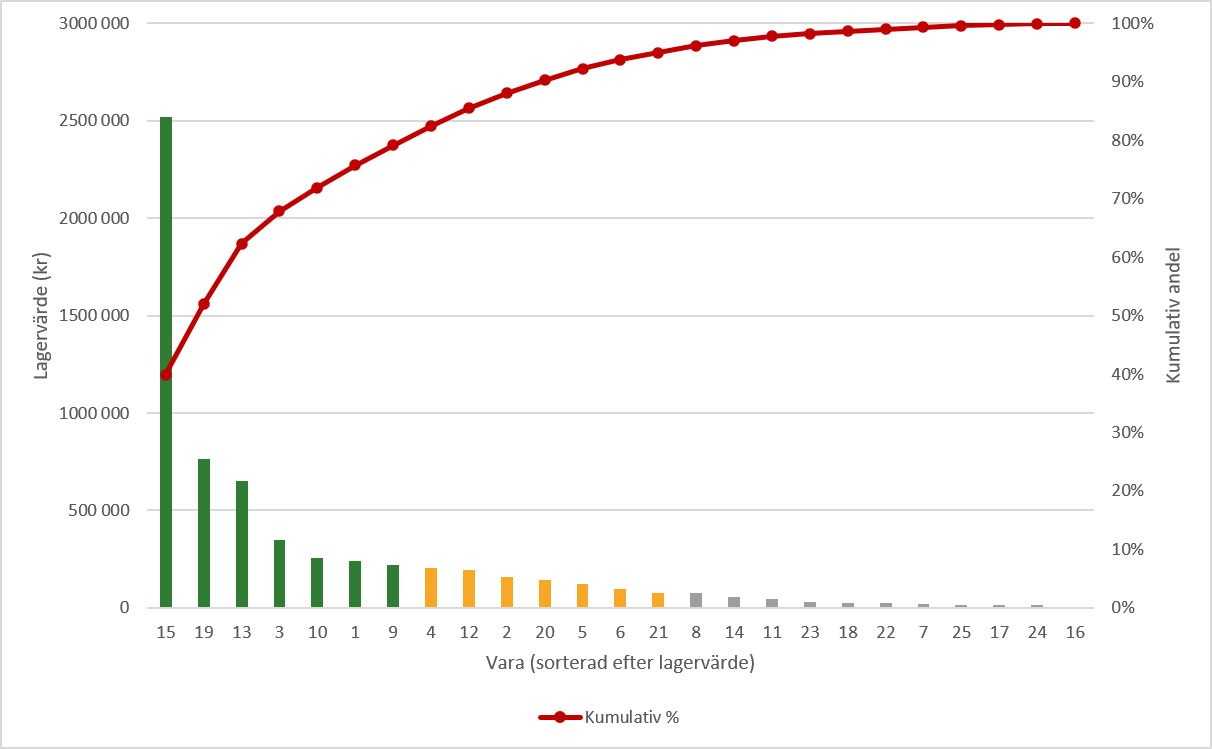

*Figur 1. Paretodiagram över ABC-analysen, gjort i Excel.*

---
# 2. Heltalsprogrammering 

I denna uppgift ska fyra arbetare genomföra sex olika arbetsuppgifter. Varje arbetsuppgift kan endast utföras av en arbetare. Arbetarna utför uppgifterna med olika arbetstider och har dessutom olika många tillgängliga arbetsdagar. Person 1 behöver två dagar för att utföra en uppgift, person 2 och 3 behöver tre dagar vardera, medan person 4 behöver fyra dagar. 

## 2a) Generell matematisk modell

**Index**

- $I = \{1,2,3,4\}$: personer
- $J = \{1,2,3,4,5,6\}$: arbetsuppgifter



**Parametrar**

- $V_{ij}$: vinst (kr) om person $i$ utför uppgift $j$
- $t_i$: antal dagar det tar för person $i$ att utföra en uppgift, $t = (2, 3, 3, 4)$
- $T_i$: antal tillgängliga dagar för person $i$, $T = (4, 4, 8, 8)$

**Målfunktionen**

Målet är att hitta den optimala lösningen där rätt person genomför rätt arbetsuppgift för att maximera den totala vinsten. Målfunktionen skrivs därför som: 


$$
\max Z = \sum_{i=1}^{4}\sum_{j=1}^{6} V_{ij}x_{ij}
$$


**Bivillkor**

Det finns två olika bivillkor i uppgiften. 

Det första bivillkoret begränsar arbetarnas arbetstid. Varje arbetare har ett begränsat antal tillgängliga arbetsdagar. 

För arbetare 1 :

$$
2\sum_{j=1}^{6}x_{1j}\leq 4
$$


För arbetare 2 :

$$
3\sum_{j=1}^{6}x_{2j}\leq 4
$$


För arbetare 3 :

$$
3\sum_{j=1}^{6}x_{3j}\leq 8
$$

För arbetare 4 : 

$$
4\sum_{j=1}^{6}x_{4j}\leq 8
$$

Det andra bivillkoret innebär att varje arbetsuppgift måste tilldelas exakt en arbetare. Därför måste summan av varje kolumn i beslutsmatrisen vara lika med ett. 


$$
\sum_{i=1}^{4}x_{ij}=1,
\quad j=1,\ldots,6
$$

**Beslutsvariabel**

$$x_{ij} = \begin{cases} 1 & \text{om person } i \text{ utför uppgift } j \\ 0 & \text{annars} \end{cases}$$
Slutligen så är beslutsvariabeln binär, vilket innebär att de endast kan vara 0 eller 1.

**Beslutmatris**

$$
X =
\begin{pmatrix}
x_{11} & x_{12} & x_{13} & x_{14} & x_{15} & x_{16} \\
x_{21} & x_{22} & x_{23} & x_{24} & x_{25} & x_{26} \\
x_{31} & x_{32} & x_{33} & x_{34} & x_{35} & x_{36} \\
x_{41} & x_{42} & x_{43} & x_{44} & x_{45} & x_{46}
\end{pmatrix}
$$


In [ ]:
V = np.array([[37000, 23000, 20000, 18000, 16000, 6000],
     [25000, 14000, 14000, 18000, 17000, 8000],
     [5000,  13000, 10000, 12000,  5000, 5000],
     [10000,  3000, 13000,  7000,  2000, 16000]
     ])

dagar = [2, 3, 3, 4]      # dagar per uppgift för person 1-4
tid = [4, 4, 8, 8]        # tillgängliga dagar för person 1-4

obj = -V.flatten()        # linprog minimerar, så vi minimerar -Z

def losa(tid):

    Aub = []
    for i in range(4):
        rad = [0] * 24
        for j in range(6):
            rad[6*i + j] = dagar[i]
        Aub.append(rad)
    Bub = tid

   
    Aeq = []
    for j in range(6):
        rad = [0] * 24
        for i in range(4):
            rad[6*i + j] = 1
        Aeq.append(rad)
    Beq = [1] * 6

    bnd = [(0, 1)] * 24        # varje x mellan 0 och 1 ...
    heltal = [1] * 24          # och heltal, alltså binär

    resultat = linprog(c=obj, A_ub=Aub, b_ub=Bub, A_eq=Aeq, b_eq=Beq,
                       bounds=bnd, integrality=heltal)

    x = np.round(resultat.x).astype(int).reshape(4, 6)   # rad = person, kolumn = uppgift
    return -resultat.fun, x

print(losa([4, 4, 8, 8]))   # a)

(118000.0, array([[1, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0, 1]]))


## 2b) Person 1 får 6 dagar

Enda ändringen i modellen är högerledet i tidsbivillkoret för person 1. Nu hinner person 1 göra 3 uppgifter.

In [978]:
print(losa([6, 4, 8, 8]))   # b) person 1 har 6 dagar

(125000.0, array([[1, 1, 1, 0, 0, 0],
       [0, 0, 0, 0, 1, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 1]]))


---
# 3. Omlastningsmodell: probabilistiska bivillkor och heltal

Fyra bruk (A, B, C, D) skickar varor via två omlastningsnoder (E, F) till tre kunder (G, H, I). Bruken kan leverera högst 400, 350, 300 och 450 enheter. Kundernas efterfrågan är osäker och normalfördelad:

| Kund | Medelvärde | Standardavvikelse |
|---|---|---|
| G | 560 | 40 |
| H | 200 | 20 |
| I | 400 | 30 |

Transportkostnad (kr/enhet):

| Från/till | E | F |
|---|---|---|
| A | 4 | 6 |
| B | 5 | 7 |
| C | 8 | 6 |
| D | 4 | 4 |

| Från/till | G | H | I |
|---|---|---|---|
| E | 2 | 3 | 1 |
| F | 2 | 2 | 4 |

### 3a) Nätverk och definitioner

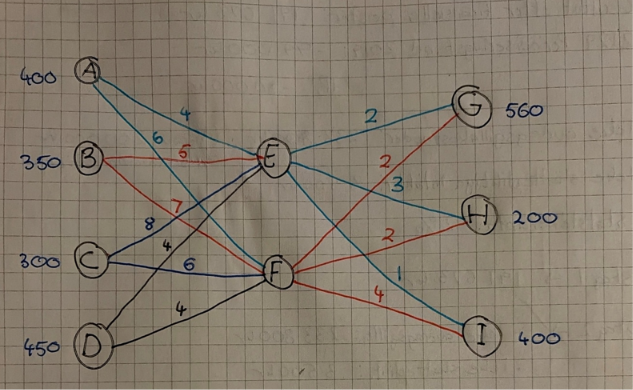

**Mängder:**

- Bruk (supplynoder): $S = \{A, B, C, D\}$
- Omlastningsnoder: $T = \{E, F\}$
- Kunder (demandnoder): $K = \{G, H, I\}$

**Parametrar:**

- $s_i$ = maximalt utbud i bruk i: $s = (400, 350, 300, 450)$
- $\mu$, $\sigma$ = medelvärde och standardavvikelse för efterfrågan hos kund
- $c_{ij}$ = transportkostnad per enhet från i till j

**Beslutsvariabler:**

- $x_{ij}$ = antal enheter som skickas från nod i till j, till exempel $x_{AE}$ från A till E

Det finns 8 länkar från bruken till omlastningen och 6 från omlastningen till kunderna, alltså 14 variabler:
$x_{AE}, x_{AF}, x_{BE}, x_{BF}, x_{CE}, x_{CF}, x_{DE}, x_{DF}, x_{EG}, x_{EH}, x_{EI}, x_{FG}, x_{FH}, x_{FI}$.

### 3b) Generell modell

**Målfunktion:** minimera den totala transportkostnaden
$$\begin{aligned}\text{Min } Z = {}& 4x_{AE} + 6x_{AF} + 5x_{BE} + 7x_{BF} + 8x_{CE} + 6x_{CF} + 4x_{DE} + 4x_{DF} \\
&+ 2x_{EG} + 3x_{EH} + x_{EI} + 2x_{FG} + 2x_{FH} + 4x_{FI}\end{aligned}$$

**Bivillkor:**

Bruken kan inte skicka mer än de har:
$$x_{AE} + x_{AF} \leq 400 \qquad x_{BE} + x_{BF} \leq 350 \qquad x_{CE} + x_{CF} \leq 300 \qquad x_{DE} + x_{DF} \leq 450$$

Allt som kommer in till en omlastningsnod ska skickas vidare, vilket vi kallar flödesbalans:
$$x_{AE} + x_{BE} + x_{CE} + x_{DE} = x_{EG} + x_{EH} + x_{EI}$$
$$x_{AF} + x_{BF} + x_{CF} + x_{DF} = x_{FG} + x_{FH} + x_{FI}$$

Kunderna ska få minst sin efterfrågan $d_k$:
$$x_{EG} + x_{FG} \geq d_G \qquad x_{EH} + x_{FH} \geq d_H \qquad x_{EI} + x_{FI} \geq d_I$$

$$x_{ij} \geq 0$$

Generellt:
$$\text{Min } Z = \sum_{(i,j)} c_{ij}\,x_{ij}, \qquad \sum_{j \in T} x_{ij} \le s_i \ \ (i \in S), \qquad \sum_{i \in S} x_{it} = \sum_{k \in K} x_{tk} \ \ (t \in T), \qquad \sum_{t \in T} x_{tk} \ge d_k \ \ (k \in K)$$

### 3c) Lösning med medelvärdet som efterfrågan

Här är $d = (560, 200, 400)$.

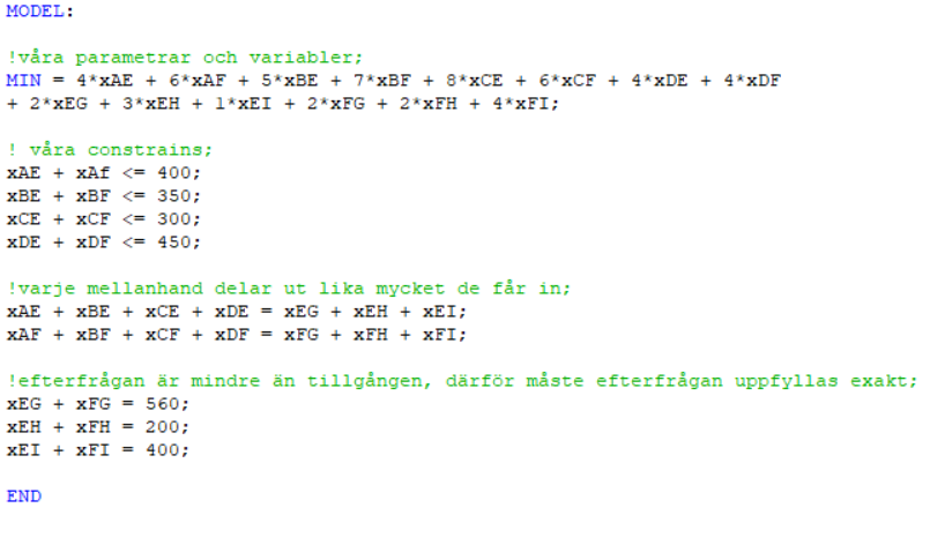

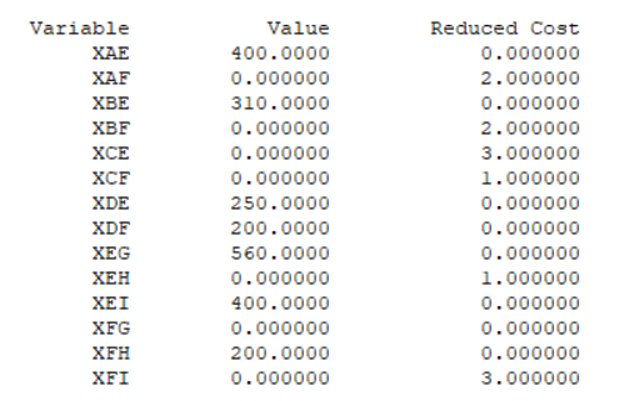

Den minsta kostnaden blir 6870 kr. Bruk C används inte alls $x_{CE} = x_{CF} = 0$, eftersom det har de högsta transportkostnaderna och de andra bruken räcker för att täcka efterfrågan, 1160 enheter mot 1200 i utbud utan C. C behövs alltså inte i den optimala lösningen.


### 3d) Probabilistiska bivillkor

Efterfrågan är osäker, så vi kräver att varje kund ska få sin efterfrågan uppfylld med minst 90 % sannolikhet:
$$P(x_{EG} + x_{FG} \geq D_G) \geq 0{,}90$$

Med standardiserad normalfördelning blir motsvarigheten
$$x_{EG} + x_{FG} \geq \mu_G + z_{0,90}\,\sigma_G, \qquad z_{0,90} = 1{,}2816,$$

alltså leveransen ska vara medelvärdet plus 1,2816 standardavvikelser. Det enda som ändras i modellen är högerleden för efterfrågan.

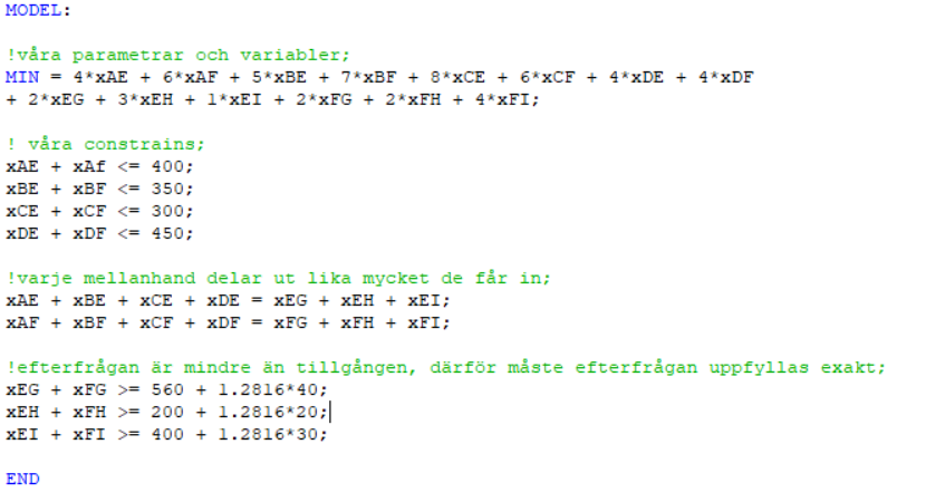

Och LINGO visar då detta:

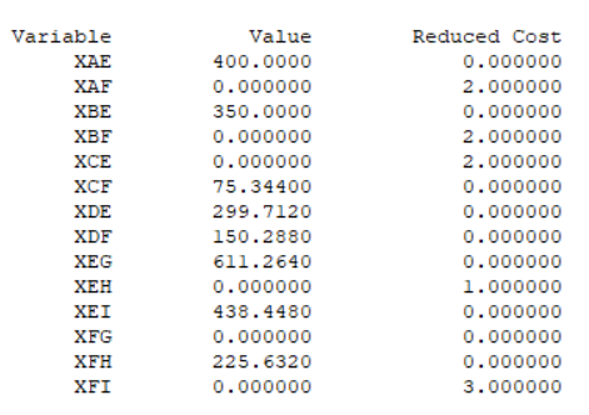

**Högre signifikansnivå.** Vi testar också 95 % och 99 %. Det enda som ändras är z-värdet i de tre efterfrågeraderna:

| Signifikansnivå | $z$ |
|---|---|
| 90 % | 1,2816 |
| 95 % | 1,6449 |
| 99 % | 2,3263 |

I LINGO byts de tre sista raderna ut. För 95 %:
```
xEG + xFG >= 560 + 1.6449*40;
xEH + xFH >= 200 + 1.6449*20;
xEI + xFI >= 400 + 1.6449*30;
```
Vilket resulterar till: 

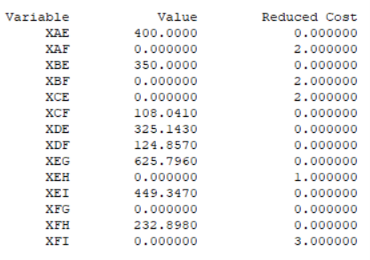

Med kostnaden 7965kr.

För 99 %:
```
xEG + xFG >= 560 + 2.3263*40;
xEH + xFH >= 200 + 2.3263*20;
xEI + xFI >= 400 + 2.3263*30;
```

Vilket resulterar till:

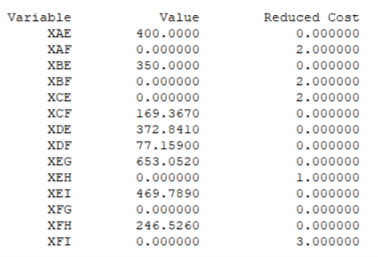

Med kostnaden 8435kr.


Kostnaden ökar alltså, enligt tabell X, med ökad signifikansnivå när vi närmar oss 100%. 

*Tabell X. Kostnader efter höjd signifikansnivå. Samt hur efterfrågan och användandet av C ändras.*

| Signifikansnivå| Total efterfrågan | Från bruk C | Kostnad |
|---|---|---|---|
| Medelvärde (c) | 1 160 | 0 | 6 870 kr |
| 90 % | 1 275 | 75 | 7 714 kr |
| 95 % | 1 308 | 108 | 7 965 kr |
| 99 % | 1 369 | 169 | 8 435 kr |

Med 90 % säkerhet ökar kostnaden från 6870 till 7714. Den totala efterfrågan som ska täckas blir 1275 enheter istället för 1160 och då räcker inte bruken A, B och D (400 + 350 + 450 = 1 200 enheter). Bruk C, som inte behövdes i uppgift c) måste nu användas och skickar ca 75 enheter via F.

### 3e) Fasta kostnader för bruken

Om vi utökar modellen i uppgift c):

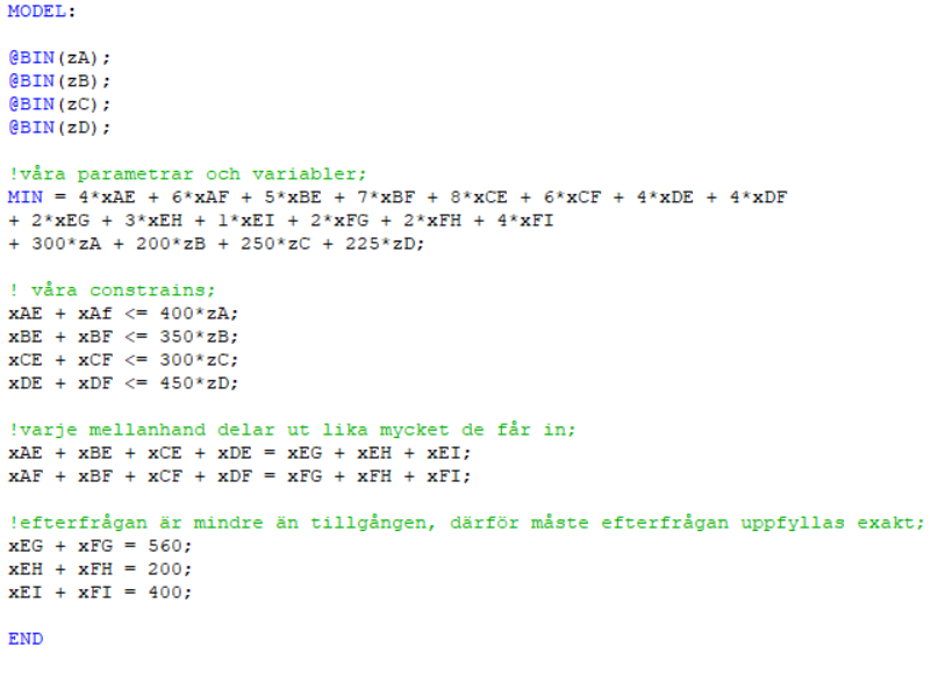

Vi får ut den minsta möjliga kostnaden 7595. Resultatet i LINGO visar:

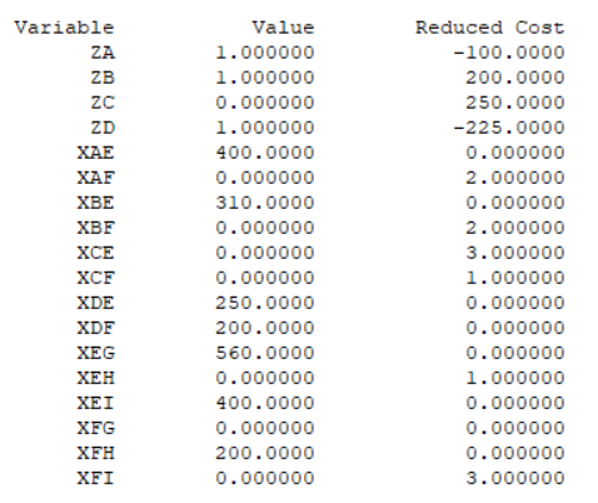

Fabrik C används alltså fortfarande inte. Alltså, om efterfrågan är medelvärdet, påverkar fasta kostnader inte strukturen i lösningen. 

Om vi istället utökar modellen i uppgift d):

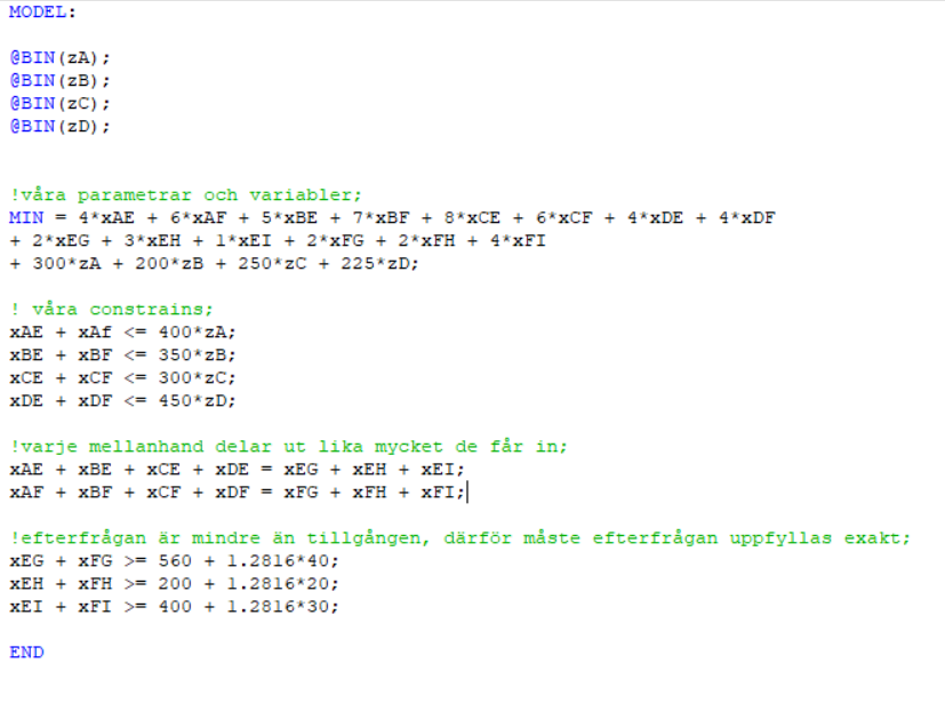

Minsta möjliga kostnaden blir 8689. I LINGO visas:

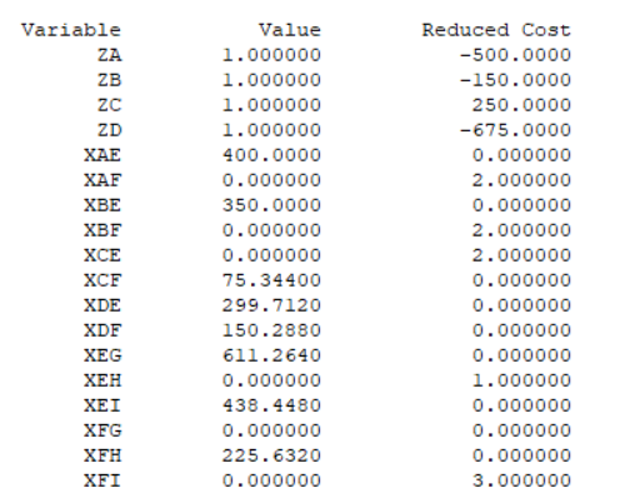

Vad händer om bruk B (mill 2) kan leverera 450 i stället för 350 enheter?

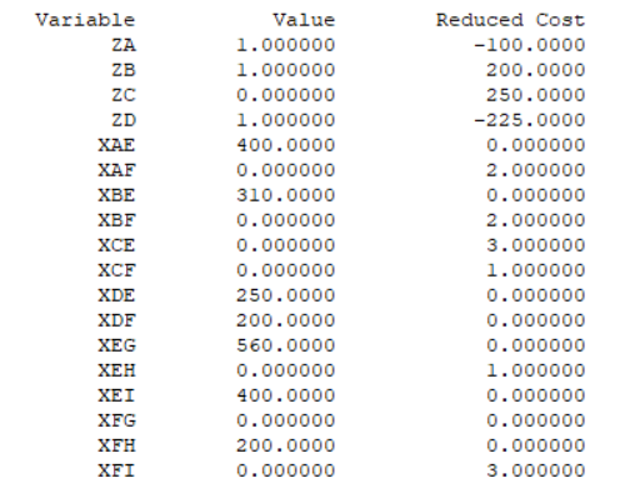

Vid användning av medelvärde påverkas inte kostnaden utan förblir 7595. Dessutom påverkas inte några variabler, alltså är lösningen exakt den samma. 

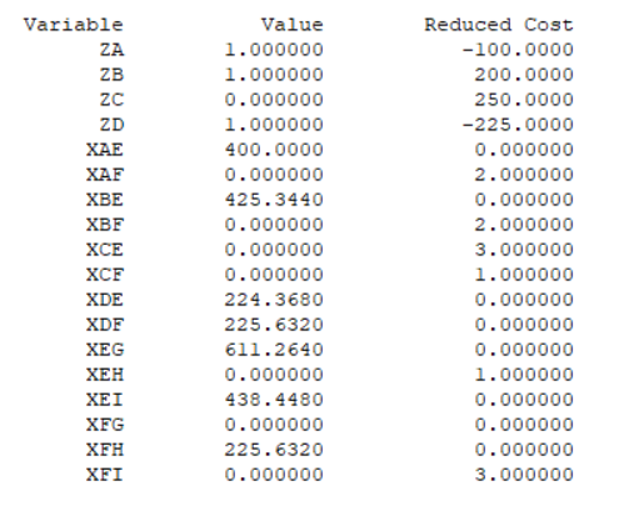

Vid användning av probalistisk begränsning och standardavvikelse ändras kostnaden till 8364. Dessutom ändras värden på några variabler. Vi kan nu se att fabrik C inte används i den optimala lösningen längre. Den ökade kapaciteten i fabrik B minskade alltså behovet av fler fabriker och kan därmed sänka totalkostnaden trots höga servicekrav. Denna modell är en Mixed Integer Linear Programming, eller MILP, mer specifikt ett fixed-charge transshipment problem. 

### 3f) Kapacitet på länkarna

Vi lägger till kapacitet på 350 på länkarna:

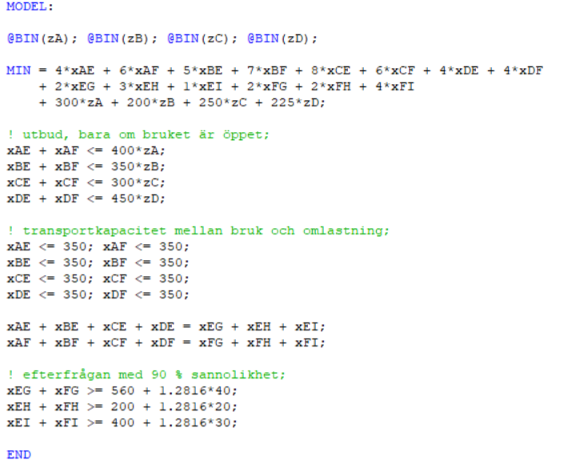

där LINGO matar ut kostnaden till ca 8789. Länkarna A-E och B-E slår i taket på 350 och flödet måste därför ta andra dyrare länkar, vilket resulterar i den högre kostnaden. 

Om kapaciteten istället ska vara samma på alla länkar och vi vill hitta den minsta kapaciteten K, matar vi detta till LINGO:

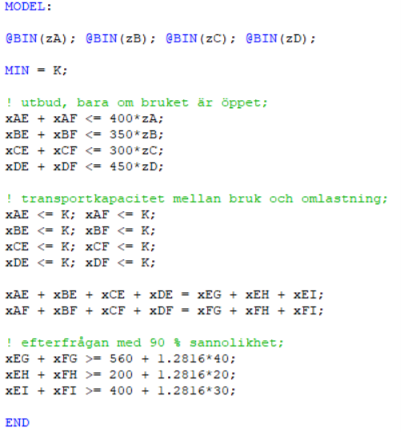

Vi får då ut att K kommer att vara 162,56

Svaren är inte heltal, eftersom 90%-efterfrågan inte är heltal. Om vi istället använder denna LINGO kod för alla 14 flöden:

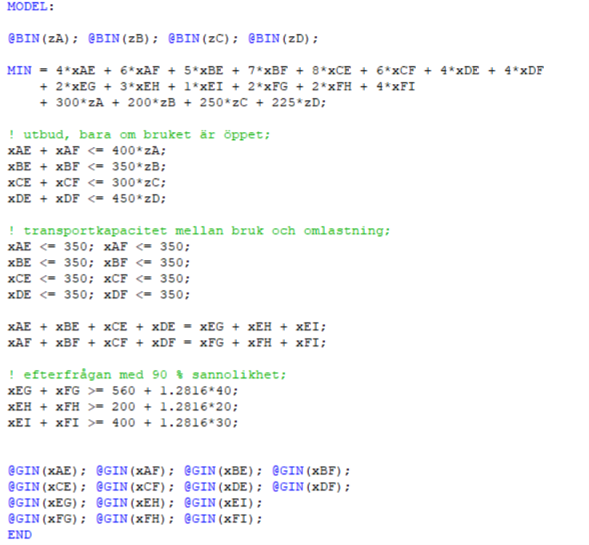

Vi får då en något högre kostnad på 8802 istället. 

Använder vi också heltal för att hitta våran gemensamma minsta kapaciteten K, gör vi:

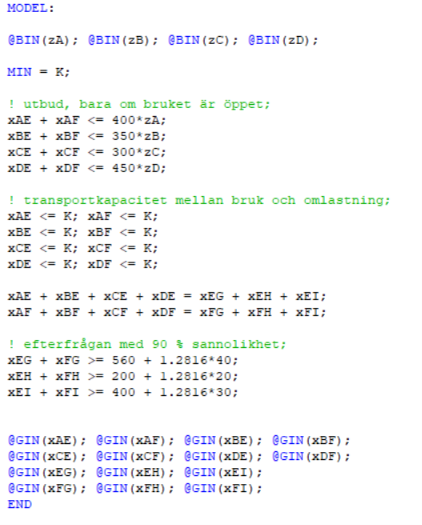

och får ut att K blir 163. 

Avrundning är överlag inte okej. Det kan bryta flödesbalansen, få ett flöde som ligger på 350 att gå över sin gräns eller göra att efterfrågan inte täcks om avrundningen görs nedåt. 

---
# 4. Intermodal transportplanering

### 4a) Generell modell
### 4b) En färja (2000 lastbilar/år)
### 4c) Fler färjor
### 4d) Minskad kapacitet på vägen 2–3

---
# 5. Tomma godsvagnar

### 5a) Nätverk och modelltyp
### 5b) Generell modell
### 5c) Lösning
### 5d) Med och utan trängselvillkor
### 5e) Känslighet för P